In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [13]:
df = pd.read_csv("Teen_Mental_Health_Dataset.csv")
df

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,18,female,6.8,Instagram,6.6,2.0,2.76,1.0,low,3,4,4,0
1196,16,male,2.3,Both,8.0,1.9,2.12,0.4,high,7,4,4,0
1197,14,female,1.7,Both,8.7,0.7,3.98,0.8,high,1,1,1,0
1198,15,male,3.9,Both,8.5,2.1,3.19,0.6,high,7,9,9,0


In [14]:
df.columns

Index(['age', 'gender', 'daily_social_media_hours', 'platform_usage',
       'sleep_hours', 'screen_time_before_sleep', 'academic_performance',
       'physical_activity', 'social_interaction_level', 'stress_level',
       'anxiety_level', 'addiction_level', 'depression_label'],
      dtype='str')

In [15]:
df.describe

<bound method NDFrame.describe of       age  gender  daily_social_media_hours platform_usage  sleep_hours  \
0      14    male                       7.9      Instagram          7.4   
1      19  female                       1.9         TikTok          8.0   
2      17  female                       1.3      Instagram          7.6   
3      15    male                       7.4         TikTok          6.9   
4      15  female                       4.7           Both          4.9   
...   ...     ...                       ...            ...          ...   
1195   18  female                       6.8      Instagram          6.6   
1196   16    male                       2.3           Both          8.0   
1197   14  female                       1.7           Both          8.7   
1198   15    male                       3.9           Both          8.5   
1199   16  female                       4.7         TikTok          6.5   

      screen_time_before_sleep  academic_performance  physical_ac

In [16]:
df.duplicated

<bound method DataFrame.duplicated of       age  gender  daily_social_media_hours platform_usage  sleep_hours  \
0      14    male                       7.9      Instagram          7.4   
1      19  female                       1.9         TikTok          8.0   
2      17  female                       1.3      Instagram          7.6   
3      15    male                       7.4         TikTok          6.9   
4      15  female                       4.7           Both          4.9   
...   ...     ...                       ...            ...          ...   
1195   18  female                       6.8      Instagram          6.6   
1196   16    male                       2.3           Both          8.0   
1197   14  female                       1.7           Both          8.7   
1198   15    male                       3.9           Both          8.5   
1199   16  female                       4.7         TikTok          6.5   

      screen_time_before_sleep  academic_performance  physica

In [17]:
df = df.dropna()
df

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,18,female,6.8,Instagram,6.6,2.0,2.76,1.0,low,3,4,4,0
1196,16,male,2.3,Both,8.0,1.9,2.12,0.4,high,7,4,4,0
1197,14,female,1.7,Both,8.7,0.7,3.98,0.8,high,1,1,1,0
1198,15,male,3.9,Both,8.5,2.1,3.19,0.6,high,7,9,9,0


In [18]:
df.columns

Index(['age', 'gender', 'daily_social_media_hours', 'platform_usage',
       'sleep_hours', 'screen_time_before_sleep', 'academic_performance',
       'physical_activity', 'social_interaction_level', 'stress_level',
       'anxiety_level', 'addiction_level', 'depression_label'],
      dtype='str')

In [ ]:
columns_to_track = ['age', 'daily_social_media_hours', 'sleep_hours', 'academic_performance', 'addiction_level']


In [38]:
df[columns_to_track].hist(bins=20, figsize=(10, 8))
plt.xlabel("columns_to_track")
plt.ylabel("age")
plt.tight_layout()
plt.show()

KeyError: "['gender'] not in index"

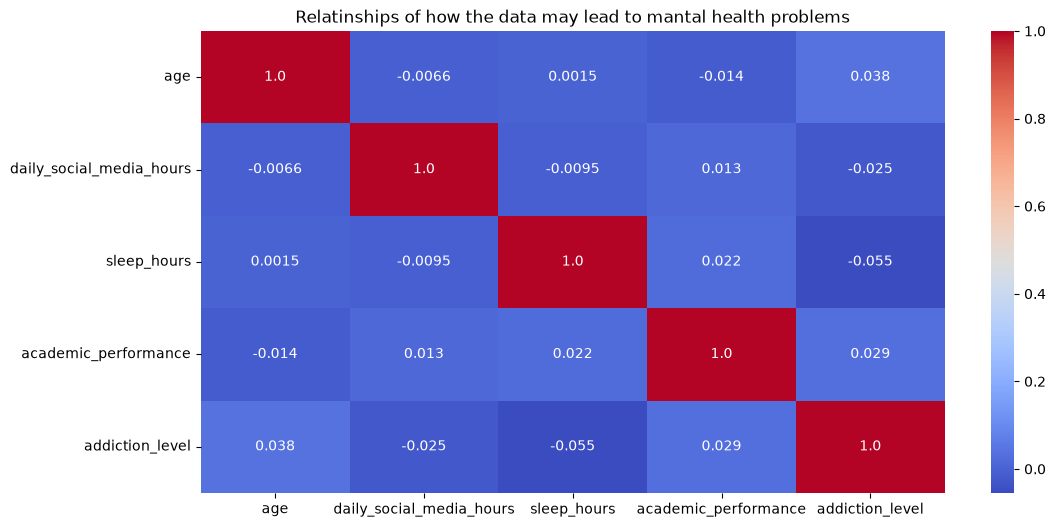

In [24]:
plt.figure(figsize=(12, 6))
sns.heatmap(df[columns_to_track].corr(), annot=True, cmap="coolwarm", fmt=".2")
plt.title("Relatinships of how the data may lead to mantal health problems")
plt.show()

In [25]:
x = df[columns_to_track].drop(columns=["age"])
y = df["age"]

In [26]:
x.head()

,daily_social_media_hours,sleep_hours,academic_performance,addiction_level
0,7.9,7.4,3.01,1
1,1.9,8.0,3.22,10
2,1.3,7.6,3.92,2
3,7.4,6.9,3.48,9
4,4.7,4.9,2.37,2


In [28]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=50)
print(f"Training setsize:{x_train.shape[0]} samples")
print(f"Test setsize:{x_test.shape[0]} samples")

Training setsize:960 samples
Test setsize:240 samples


In [29]:
model = LinearRegression()
model.fit(x_train, y_train)
    

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
coefficient = pd.DataFrame({
    
})